# Spatial Blocks


<b> Objective: </b>
Test the same datasets on spatial cross validation rather than random CV.

----------------------

<i><b>Author: </b> Salvador Palma <br>
<b>Institution: </b> Copenhagen University </i>

## Setup

In [1]:
import sys
import os
COLAB_SESSION = False

DRIVE_PATH = ""
if COLAB_SESSION:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=True)
    DRIVE_PATH = "/content/drive/MyDrive/UCPH/POOCS/"
    sys.path.insert(0, DRIVE_PATH)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from GreenlandUtils import *
from ModelUtils import *

In [ ]:
DATA_PATH = "Data/Pierpaolo/Data.csv"
RESULTS_PATH = "Results/Pierpaolo/Spatial/"
os.makedirs(f"{DRIVE_PATH}{RESULTS_PATH}", exist_ok=True)

ELEMENTS = ["Cu", "Pb", "Zn", "Mo", "W", "Sb", "Ba", "Sr"]
RATIOS = [("Cu", "Pb"), ("Cu", "Zn"), ("Mo", "Pb"), ("Mo", "Sb"), ("W", "Pb"), ("W", "Sb"), ("Ba", "Sr")]

TARGETS = [f"{e} ppm" for e in ELEMENTS] + [f"{a}/{b}" for a, b in RATIOS]

#Part 1 Best Setup
MODEL_TYPE = "hgb"
K = 20
N_FOLDS = 5
SEED = 42

In [4]:
df = pd.read_csv(f"{DRIVE_PATH}{DATA_PATH}", delimiter=";")
x, y = lonlatToUTM24N(df["Longitude"].to_numpy(float), df["Latitude"].to_numpy(float))
df["x_km"], df["y_km"] = x / 1000, y / 1000

nonFeatures = ["Sampleno", "Batch", "Latitude", "Longitude", "x_km", "y_km"] + [f"{a}/{b}" for a, b in RATIOS]
elementCols = [c for c in df.columns if c not in nonFeatures]

def TargetCols(target: str) -> list[str]:
    if "/" in target: #If ratio hide the og elements
        a, b = target.split("/")
        return [c for c in elementCols if c not in (f"{a} ppm", f"{b} ppm")]
    return elementCols


printable = Printable()
printable.title("Pierpaolo")
printable.add("Samples", len(df))
printable.add("Locations", df[["x_km", "y_km"]].drop_duplicates().shape[0])
printable.add("Element features", len(elementCols))
printable.add("Extent", f"{np.ptp(df['x_km']):.0f} x {np.ptp(df['y_km']):.0f} km")
printable.rest()

for target in TARGETS:
    printable.add(target, f"{df[target].notna().sum():>5} values")

printable.flush()

========== Pierpaolo ==========
Samples:            4000
Locations:          1668
Element features:   59
Extent:             123 x 187 km


Cu ppm:              3586 values
Pb ppm:              3140 values
Zn ppm:              2462 values
Mo ppm:              1669 values
W ppm:                686 values
Sb ppm:               538 values
Ba ppm:              2171 values
Sr ppm:               862 values
Cu/Pb:               3010 values
Cu/Zn:               2356 values
Mo/Pb:               1596 values
Mo/Sb:                487 values
W/Pb:                 599 values
W/Sb:                 409 values
Ba/Sr:                491 values


## Spatial Folds

### Blocks and Buffer

The area is cut into `blockKm` squares and whole blocks are assigned to folds, balancing sample counts. Random CV is the same code with every location as its own block, so the KNN exclusion below matches Part 1's co-location exclusion.

The buffer drops training samples within `bufferKm` of any test sample.

In [ ]:
import warnings
from sklearn.neighbors import NearestNeighbors



def SpatialFolds(df: pd.DataFrame, blockKm: float, n: int = N_FOLDS) -> tuple[np.ndarray, np.ndarray]:
    block = (np.floor(df["x_km"] / blockKm).astype(int).astype(str) + "_" + np.floor(df["y_km"] / blockKm).astype(int).astype(str))
    sizes = block.value_counts().sample(frac=1, random_state=SEED).sort_values(ascending=False, kind="stable")
    
    #keep track of load for fairest assignment possible
    load, assignment = np.zeros(n), {} 
    for name, size in sizes.items():
        fold = int(np.argmin(load))
        assignment[name] = fold
        load[fold] += size
        
    return block.map(assignment).to_numpy(), block.to_numpy()


def RandomFolds(df: pd.DataFrame, n: int = N_FOLDS) -> tuple[np.ndarray, np.ndarray]:
    location = df["x_km"].round(3).astype(str) + "_" + df["y_km"].round(3).astype(str)
    return np.random.default_rng(SEED).permutation(len(df)) % n, location.to_numpy()


def Buffer(train: pd.DataFrame, test: pd.DataFrame, bufferKm: float) -> pd.DataFrame:
    if bufferKm <= 0:
        return train
    dist, _ = NearestNeighbors(n_neighbors=1).fit(test[["x_km", "y_km"]].to_numpy()).kneighbors(train[["x_km", "y_km"]].to_numpy())
    return train[dist[:, 0] > bufferKm]

### KNN C Features

In [ ]:
def KNNFeatures(pool: pd.DataFrame, query: pd.DataFrame, k: int = K) -> pd.DataFrame:
    xy, values = pool[["x_km", "y_km"]].to_numpy(), pool[elementCols].to_numpy(float)
    poolBlocks = pool["block"].to_numpy()
    rows = pd.Series(np.arange(len(query)), index=query.index)
    out = np.full((len(query), len(elementCols)), np.nan)

    for block, part in query.groupby("block"):
        keep = poolBlocks != block
        _, pos = NearestNeighbors(n_neighbors=min(k, keep.sum())).fit(xy[keep]).kneighbors(part[["x_km", "y_km"]].to_numpy())
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            out[rows[part.index]] = np.nanmean(values[keep][pos], axis=1)

    return pd.DataFrame(out, index=query.index, columns=[f"{k}-KNN_{e}_mean" for e in elementCols])


def FoldData(frame: pd.DataFrame, fold: int, bufferKm: float = 0) -> tuple[pd.DataFrame, pd.DataFrame]:
    test = frame[frame["fold"] == fold]
    train = Buffer(frame[frame["fold"] != fold], test, bufferKm)
    return (pd.concat([train, KNNFeatures(train, train)], axis=1), pd.concat([test, KNNFeatures(train, test)], axis=1))


KNN_COLS = [f"{K}-KNN_{e}_mean" for e in elementCols]

### Sanity Check

============================== Fold 1 ==============================
Random CV:                    train  3200   test   800   buffered     0
10 km blocks:                 train  3200   test   800   buffered     0
10 km blocks + 2 km buffer:   train  3018   test   800   buffered   182


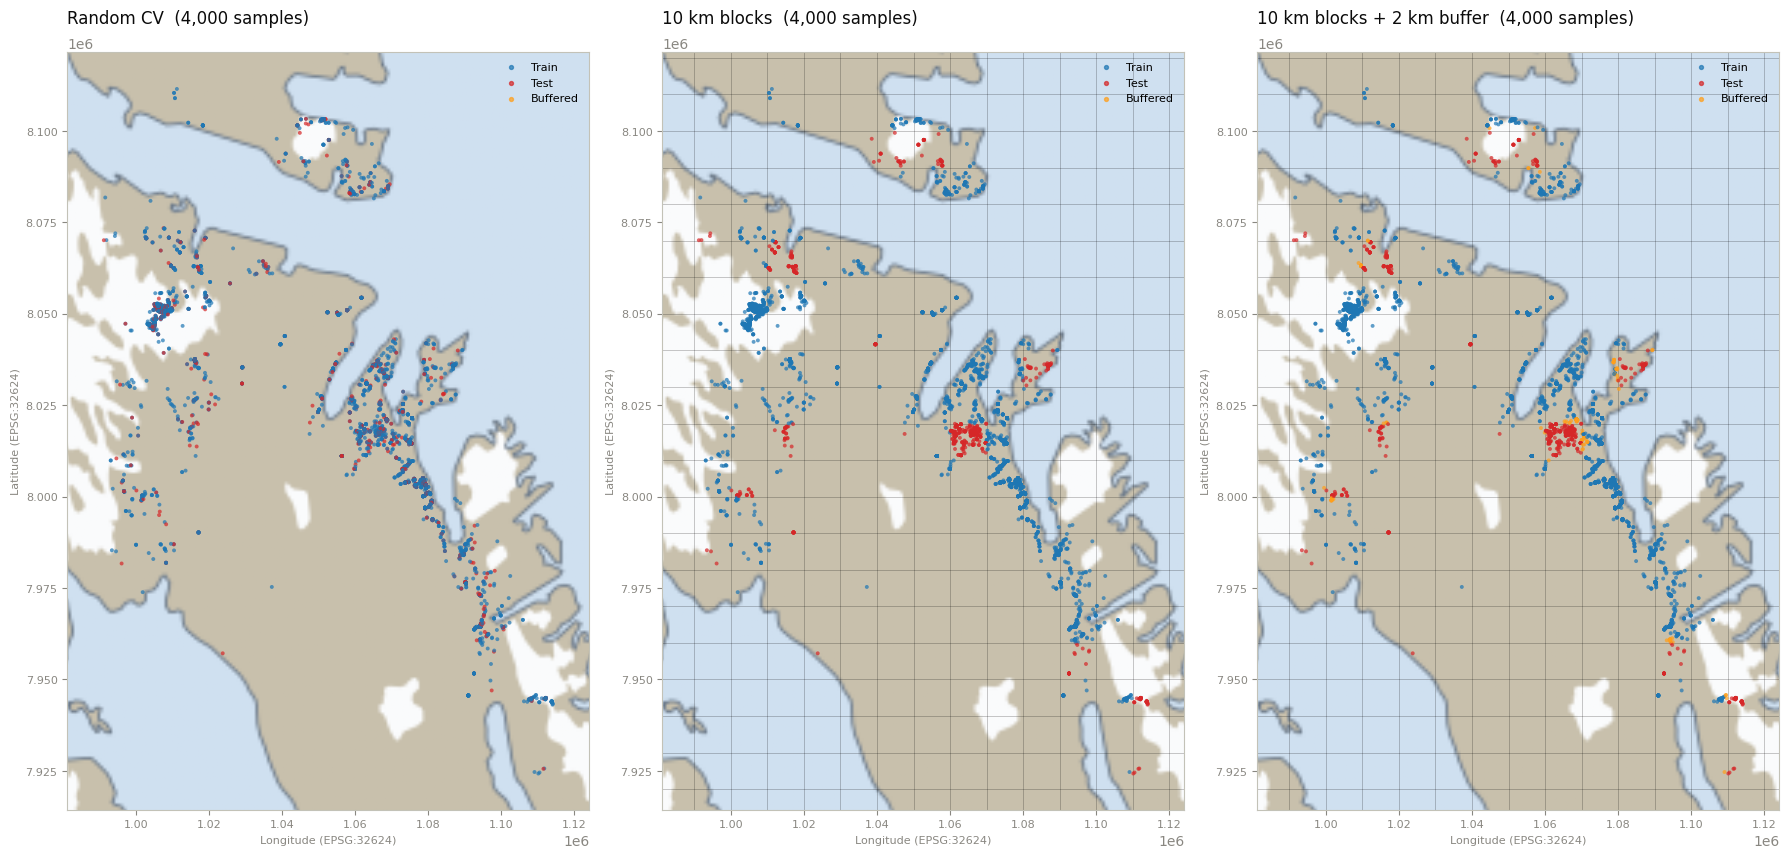

In [ ]:
SETUPS = {
    "Random CV": RandomFolds(df),
    "10 km blocks": SpatialFolds(df, 10),
    "10 km blocks + 2 km buffer": SpatialFolds(df, 10),
}
BUFFERS = {"Random CV": 0, "10 km blocks": 0, "10 km blocks + 2 km buffer": 2}
BLOCK_KM = {"Random CV": 0, "10 km blocks": 10, "10 km blocks + 2 km buffer": 10}
GRID_ALPHA = 0.3


def DrawBlocks(ax, blockKm: float, alpha: float = GRID_ALPHA):
    if alpha <= 0 or blockKm <= 0:
        return
    step = blockKm * 1000
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    for x in np.arange(np.floor(x0 / step) * step, x1, step):
        ax.axvline(x, color="black", linewidth=0.5, alpha=alpha, zorder=1)
    for y in np.arange(np.floor(y0 / step) * step, y1, step):
        ax.axhline(y, color="black", linewidth=0.5, alpha=alpha, zorder=1)

fig, axes = plt.subplots(1, 3, figsize=(18, 9))

printable = Printable()
printable.title("Fold 1")

for ax, (name, (folds, blocks)) in zip(axes, SETUPS.items()):

    frame = df.assign(fold=folds, block=blocks)
    train, test = FoldData(frame, 0, BUFFERS[name])

    frame["colors"] = "#ff9f1c"
    frame.loc[train.index, "colors"] = "#1f77b4"
    frame.loc[test.index, "colors"] = "#d62728"

    PlotSamplesOnMap(frame, title=name, ax=ax, pointSize=8, colorLabels={"Train": "#1f77b4", "Test": "#d62728", "Buffered": "#ff9f1c"})
    
    ax.set_xlim(df["x_km"].min() * 1000 - 10_000, df["x_km"].max() * 1000 + 10_000)
    ax.set_ylim(df["y_km"].min() * 1000 - 10_000, df["y_km"].max() * 1000 + 10_000)
    
    DrawBlocks(ax, BLOCK_KM[name])
    printable.add(name, f"train {len(train):>5}   test {len(test):>5}   buffered {len(frame) - len(train) - len(test):>5}")

printable.flush()

plt.tight_layout()
plt.show()



In [15]:
table = pd.DataFrame(index=pd.Index(range(1, N_FOLDS + 1), name="fold"))
for name, (folds, blocks) in SETUPS.items():
    cells = []
    for f in range(N_FOLDS):
        test = df[folds == f]
        train = Buffer(df[folds != f], test, BUFFERS[name])
        buffered = 100 * (len(df) - len(train) - len(test)) / len(df)
        cell = f"{100 * len(train) / len(df):.1f} / {100 * len(test) / len(df):.1f}"
        cells.append(cell + (f" ({buffered:.1f} buffered)" if buffered else ""))
    table[name] = cells

display(table)

,Random CV,10 km blocks,10 km blocks + 2 km buffer
fold,,,
1,80.0 / 20.0,80.0 / 20.0,75.5 / 20.0 (4.5 buffered)
2,80.0 / 20.0,80.0 / 20.0,74.8 / 20.0 (5.2 buffered)
3,80.0 / 20.0,80.0 / 20.0,68.0 / 20.0 (12.0 buffered)
4,80.0 / 20.0,80.0 / 20.0,76.1 / 20.0 (3.9 buffered)
5,80.0 / 20.0,80.0 / 20.0,70.2 / 20.0 (9.8 buffered)
